In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [3]:
polity = pd.read_excel('/Users/naicadena/Documents/Projects/polity-project /p5v2018.xls')
polity.head()


,p5,cyear,ccode,scode,country,year,flag,fragment,democ,autoc,...,interim,bmonth,bday,byear,bprec,post,change,d5,sf,regtrans
0,0,7001800,700,AFG,Afghanistan,1800,0,NaN,1,7,...,NaN,1.0,1.0,1800.0,1.0,-6.0,88.0,1.0,NaN,NaN
1,0,7001801,700,AFG,Afghanistan,1801,0,NaN,1,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0,7001802,700,AFG,Afghanistan,1802,0,NaN,1,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0,7001803,700,AFG,Afghanistan,1803,0,NaN,1,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,7001804,700,AFG,Afghanistan,1804,0,NaN,1,7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print("Filas, columnas:", polity.shape)
print(polity.info())



Filas, columnas: (17574, 37)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17574 entries, 0 to 17573
Data columns (total 37 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   p5        17574 non-null  int64  
 1   cyear     17574 non-null  int64  
 2   ccode     17574 non-null  int64  
 3   scode     17574 non-null  object 
 4   country   17574 non-null  object 
 5   year      17574 non-null  int64  
 6   flag      17574 non-null  int64  
 7   fragment  3446 non-null   float64
 8   democ     17574 non-null  int64  
 9   autoc     17574 non-null  int64  
 10  polity    17574 non-null  int64  
 11  polity2   17307 non-null  float64
 12  durable   16310 non-null  float64
 13  xrreg     17574 non-null  int64  
 14  xrcomp    17574 non-null  int64  
 15  xropen    17574 non-null  int64  
 16  xconst    17574 non-null  int64  
 17  parreg    17574 non-null  int64  
 18  parcomp   17574 non-null  int64  
 19  exrec     17391 non-null  float64
 20 

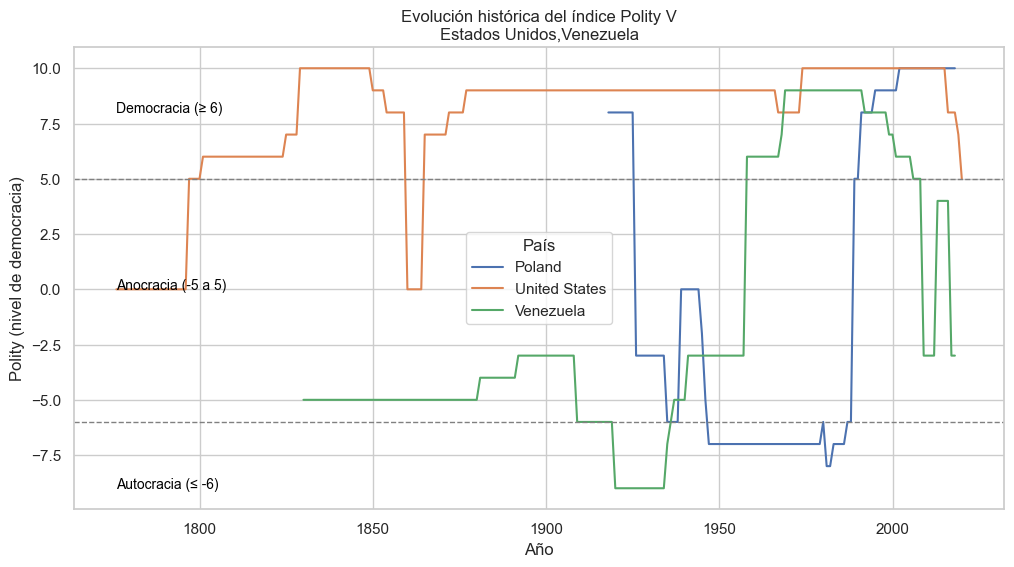

In [23]:
countries = ["United States", "Venezuela", "Poland"]
df_c = polity[polity["country"].isin(countries)]

plt.figure(figsize=(12,6))
sns.lineplot(data=df_c, x="year", y="polity2", hue="country")

plt.title("Evolución histórica del índice Polity V\nEstados Unidos,Venezuela")
plt.ylabel("Polity (nivel de democracia)")
plt.xlabel("Año")

# Líneas horizontales que marcan los regímenes
plt.axhline(-6, color="gray", linestyle="--", linewidth=1)
plt.axhline(5, color="gray", linestyle="--", linewidth=1)

# Texto explicativo (leyenda conceptual)
plt.text(
    df_c["year"].min(), 8,
    "Democracia (≥ 6)",
    fontsize=10,
    color="black"
)

plt.text(
    df_c["year"].min(), 0,
    "Anocracia (-5 a 5)",
    fontsize=10,
    color="black"
)

plt.text(
    df_c["year"].min(), -9,
    "Autocracia (≤ -6)",
    fontsize=10,
    color="black"
)

plt.legend(title="País")
plt.show()



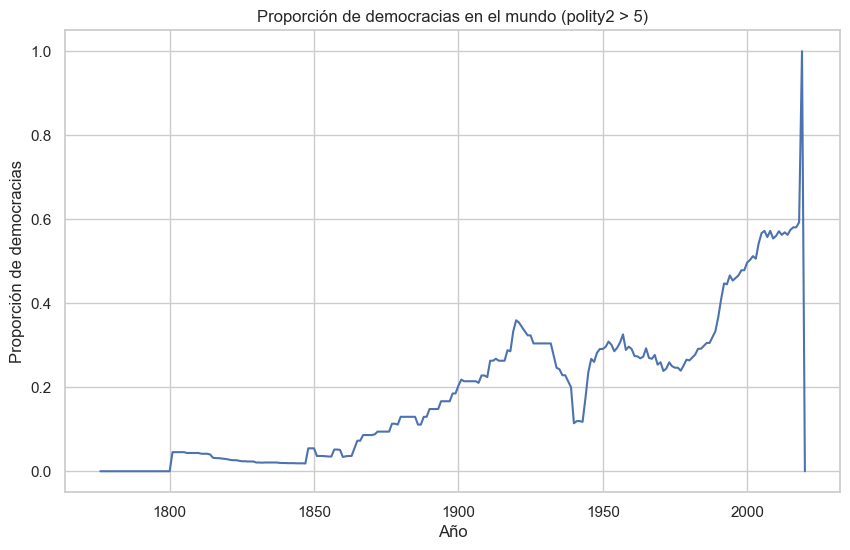

In [6]:
polity["is_dem"] = np.where(polity["polity2"] > 5, 1, 0)

df_prop = (
    polity.groupby("year")["is_dem"]
          .mean()
          .reset_index(name="prop_dem")
)

plt.figure(figsize=(10,6))
sns.lineplot(data=df_prop, x="year", y="prop_dem")
plt.title("Proporción de democracias en el mundo (polity2 > 5)")
plt.ylabel("Proporción de democracias")
plt.xlabel("Año")
plt.show()


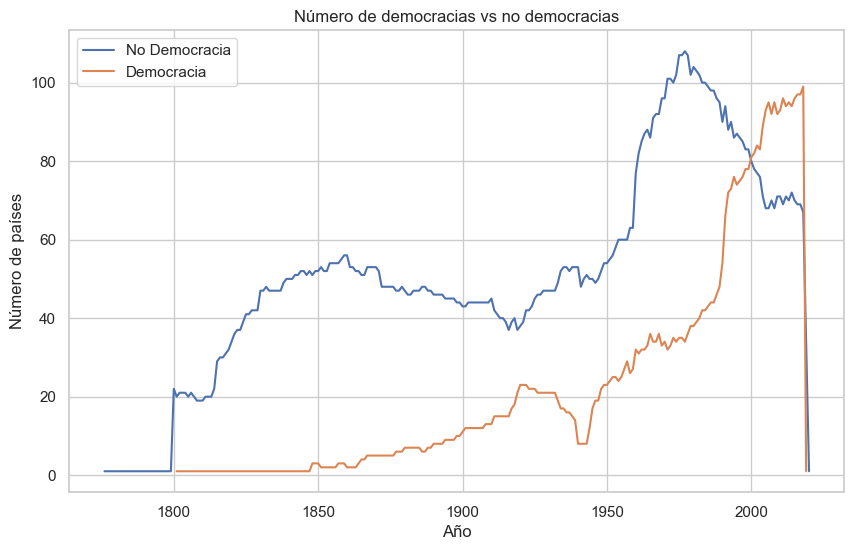

In [13]:
# numero de democracias vs no democracias 
polity_valid = polity[
    polity["polity2"].between(-10, 10)
].copy()


polity_valid["group"] = np.where(
    polity_valid["polity2"] > 5,
    "Democracia",
    "No Democracia"
)


df_count = (
    polity_valid
    .groupby(["year", "group"])
    .size()
    .reset_index(name="count")
)


plt.figure(figsize=(10,6))
sns.lineplot(data=df_count, x="year", y="count", hue="group")
plt.title("Número de democracias vs no democracias")
plt.xlabel("Año")
plt.ylabel("Número de países")
plt.legend(title="")
plt.show()


In [ ]:
#Países que cambiaron su nivel de democracia entre 2017 y 2018

df_1718 = polity[polity["year"].isin([2017,2018])]

df_changed = (
    df_1718.groupby("country")["polity2"]
           .agg(first_val=lambda x: x.iloc[0], last_val=lambda x: x.iloc[-1])
           .reset_index()
)

df_changed = df_changed[df_changed["first_val"] != df_changed["last_val"]]
df_changed.sort_values("country")


,country,first_val,last_val
5,Armenia,5.0,7.0
10,Bangladesh,1.0,-6.0
14,Bhutan,5.0,7.0
16,Bosnia,NaN,NaN
31,Comoros,9.0,-3.0
37,Cuba,-7.0,-5.0
49,Ethiopia,-3.0,1.0
87,Liberia,6.0,7.0
94,Malaysia,5.0,7.0
106,Nepal,6.0,7.0
